In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Лабораторная работа №1
- Напишите программу для распознавания растровых изображений, используя метод k ближайшего соседа (kNN). 
- Реализуйте программно равномерное и неравномерное зашумление изображений и сравните процент распознавания для используемых норм в случаях распознавания растровых бинарных изображений и изображений в градациях серого цвета для различных k. 
- В качестве мер близости используйте предложенные выше и сравните результаты их применения.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [3]:
SEED = 42

if "df" not in globals():
    df = fetch_openml("mnist_784")

In [4]:
df.target

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [5]:
X = df.data.to_numpy()
y = df.target.to_numpy().astype(int)

X.shape

(70000, 784)

In [6]:
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

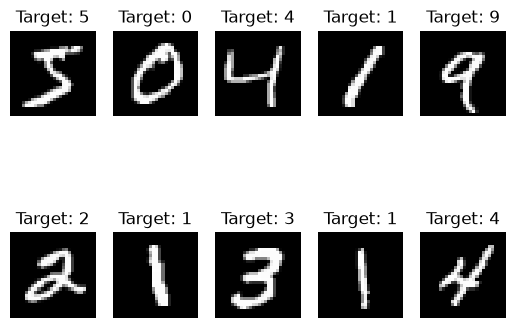

In [7]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Target: {df.target[i]}")
    plt.axis("off")

In [8]:
rng = np.random.default_rng(SEED)
tr = rng.choice(len(X_train), size=10000, replace=False)
te = rng.choice(len(X_test), size=1000, replace=False)

Xtr = (
    X_train[tr]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
) / 255

Xte = (
    X_test[te]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
    / 255
)

ytr, yte = y_train[tr], y_test[te]

Xtr_bin, Xte_bin = (Xtr > 0.5).astype(np.float32), (Xte > 0.5).astype(np.float32)

[(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5)),
 (np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))]

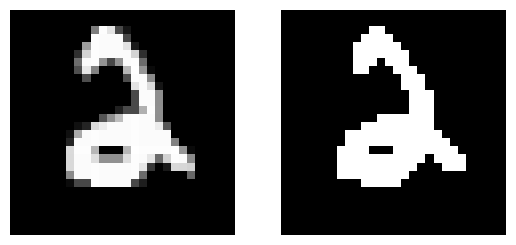

In [9]:
fig, axes = plt.subplots(1, 2)
axes[0].imshow(Xtr[0].reshape(28, 28), cmap="gray")
axes[1].imshow(Xtr_bin[0].reshape(28, 28), cmap="gray")
[ax.axis("off") for ax in axes]

### Функции зашумления: для бинарных и оттенков серого - равномерное и неравномерное
Реализованы две трактовки «равномерного / неравномерного» шума:

**1. Пространственная** (уровень `p` — доля заменённых пикселей). Пиксель с вероятностью `p` заменяется случайным значением из области значений изображения: у бинарных — случайным битом, у серых — случайной яркостью
- *равномерный* — вероятность `p` одинакова для всех пикселей;
- *неравномерный* — вероятность линейно растёт слева направо от 0 до `2p`


**2. По закону распределения** К пикселю прибавляется случайная величина:
- *равномерный* — из U(−a, a), где a = σ√3;
- *неравномерный* — из нормального N(0, σ²).

Серые после этого обрезаются в [0, 1], бинарные заново бинаризуются по порогу 0.5.

In [ ]:
def make_map(p):
    """Карта вероятностей: линейно от 0 (левый столбец) до 2p (правый столбец), в среднем p"""
    t = np.arange(28) / 27
    m = t[None, :]
    return np.broadcast_to(m, (28, 28)).ravel() * min(2 * p, 1.0)


def noise_uni_bin(X, p=0.1):
    """Равномерное зашумление бинарного изображения: с вероятностью p пиксель заменяется случайным битом"""
    mask = rng.random(X.shape) < p
    return np.where(mask, rng.random(X.shape) < 0.5, X).astype(np.float32)


def noise_nonuni_bin(X, p=0.1):
    """Неравномерное зашумление бинарного изображения: вероятность замены на случайный бит растёт слева направо, в среднем p"""
    mask = rng.random(X.shape) < make_map(p)
    return np.where(mask, rng.random(X.shape) < 0.5, X).astype(np.float32)


def noise_uni_gray(X, p=0.1):
    """Равномерное зашумление серого (255) изображения: с вероятностью p пиксель заменяется случайной яркостью"""
    mask = rng.random(X.shape) < p
    return np.where(mask, rng.random(X.shape, dtype=np.float32), X)


def noise_nonuni_gray(X, p=0.1):
    """Неравномерное зашумление серого (255) изображения: вероятность замены растёт слева направо, в среднем p"""
    mask = rng.random(X.shape) < make_map(p)
    return np.where(mask, rng.random(X.shape, dtype=np.float32), X)


def add_uniform(shape, sigma):
    """Добавка из U(-a, a): a = sigma * √3"""
    a = sigma * 3**0.5
    return (2 * rng.random(shape, dtype=np.float32) - 1) * a


def add_normal(shape, sigma):
    """Добавка из N(0, sigma^2)"""
    return sigma * rng.standard_normal(shape, dtype=np.float32)


def noise_add_uni_bin(X, sigma=0.1):
    """Аддитивный равномерный шум U(-a, a), затем повторная бинаризация по порогу 0.5"""
    return (X + add_uniform(X.shape, sigma) > 0.5).astype(np.float32)


def noise_add_norm_bin(X, sigma=0.1):
    """Аддитивный нормальный шум N(0, σ²), затем повторная бинаризация по порогу 0.5"""
    return (X + add_normal(X.shape, sigma) > 0.5).astype(np.float32)


def noise_add_uni_gray(X, sigma=0.1):
    """Аддитивный равномерный шум U(-a, a), результат обрезается в [0, 1]"""
    return np.clip(X + add_uniform(X.shape, sigma), 0, 1)


def noise_add_norm_gray(X, sigma=0.1):
    """Аддитивный нормальный шум N(0, σ²), результат обрезается в [0, 1]"""
    return np.clip(X + add_normal(X.shape, sigma), 0, 1)

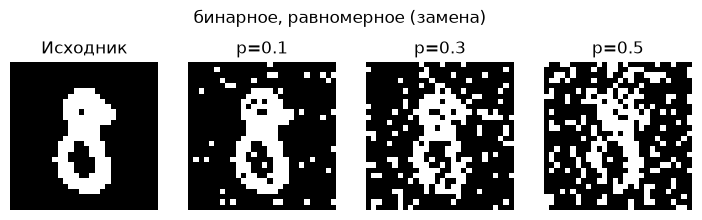

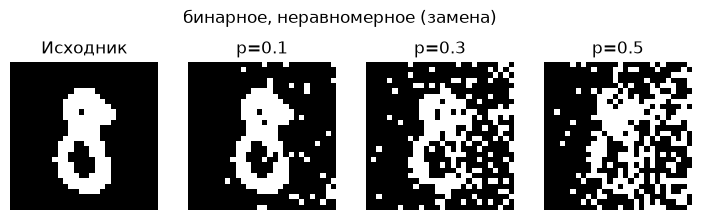

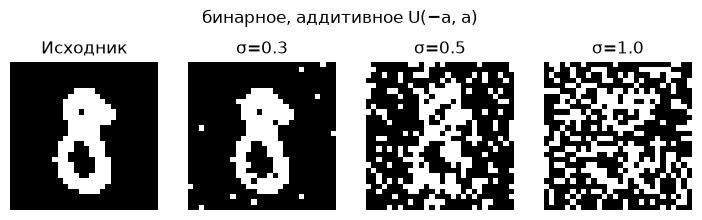

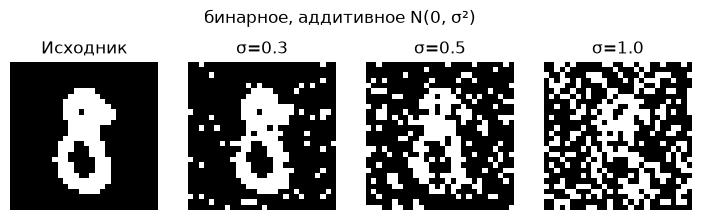

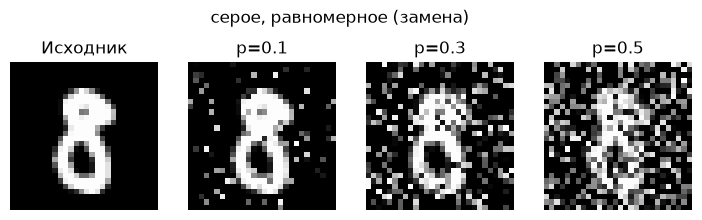

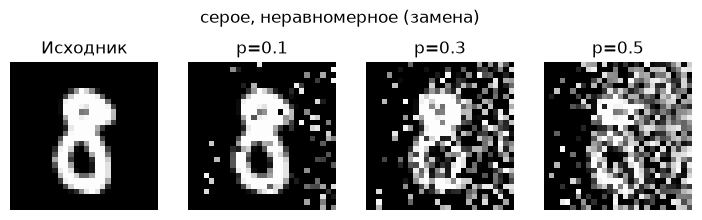

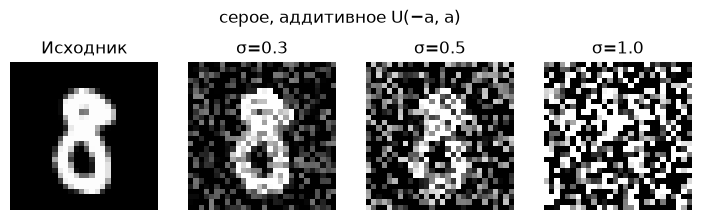

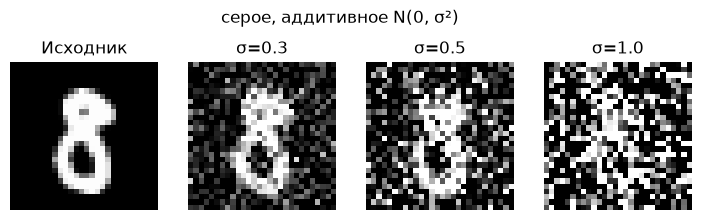

In [11]:
i = 0


def show_noise(x, fn, levels=(0.1, 0.3, 0.5), title="", name="p"):
    fig, axes = plt.subplots(1, len(levels) + 1, figsize=(2.2 * (len(levels) + 1), 2.6))
    axes[0].imshow(x.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Исходник")
    for ax, lvl in zip(axes[1:], levels):
        ax.imshow(fn(x, lvl).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{name}={lvl}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


SIGMA_DEMO = (0.3, 0.5, 1.0)

show_noise(Xte_bin[i], noise_uni_bin, title="бинарное, равномерное (замена)")
show_noise(Xte_bin[i], noise_nonuni_bin, title="бинарное, неравномерное (замена)")
show_noise(
    Xte_bin[i], noise_add_uni_bin, SIGMA_DEMO, "бинарное, аддитивное U(−a, a)", "σ"
)
show_noise(
    Xte_bin[i], noise_add_norm_bin, SIGMA_DEMO, "бинарное, аддитивное N(0, σ²)", "σ"
)
show_noise(Xte[i], noise_uni_gray, title="серое, равномерное (замена)")
show_noise(Xte[i], noise_nonuni_gray, title="серое, неравномерное (замена)")
show_noise(Xte[i], noise_add_uni_gray, SIGMA_DEMO, "серое, аддитивное U(−a, a)", "σ")
show_noise(Xte[i], noise_add_norm_gray, SIGMA_DEMO, "серое, аддитивное N(0, σ²)", "σ")

### Функции расстояния.
*Меры:*
- Евклидово	```p(a, b) = √Σ(aᵢ − bᵢ)²```
- Квадрат евклидова	```p(a, b) = Σ(aᵢ − bᵢ)²```
- Взвешенное евклидово	```p(a, b) = √Σ wᵢ(aᵢ − bᵢ)²```
- Манхэттенское	```p(a, b) = Σ|aᵢ − bᵢ|```
- Чебышёва	```p(a, b) = max|aᵢ − bᵢ|```

In [12]:
def euclidean(A, B, squared=False):
    a2 = (A**2).sum(axis=1)[:, None]
    b2 = (B**2).sum(axis=1)[None, :]
    d2 = a2 + b2 - 2.0 * (A @ B.T)
    np.maximum(d2, 0, out=d2)
    return d2 if squared else np.sqrt(d2)


def manhattan(A, B, batch=16):
    D = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(0, len(A), batch):
        chunk = A[i : i + batch]
        diff = np.abs(chunk[:, None, :] - B[None, :, :])
        D[i : i + batch] = diff.sum(axis=-1)
    return D


def weighted_euclidean(A, B, w, squared=False):
    s = np.sqrt(w).astype(np.float32)
    return euclidean(s * A, s * B, squared=squared)


def chebyshev(A, B, batch=16):
    D = np.empty((len(A), len(B)), dtype=np.float32)
    for i in range(0, len(A), batch):
        chunk = A[i : i + batch]
        diff = np.abs(chunk[:, None, :] - B[None, :, :])
        D[i : i + batch] = diff.max(axis=-1)
    return D

### Реализация kNN

In [13]:
from collections import Counter, defaultdict


# Not optimized
def knn(
    D: np.ndarray, ytr: np.ndarray, yte: np.ndarray, key: list[int]
) -> dict[int, float]:
    idx = np.argsort(D, axis=1)
    counts = defaultdict(int)
    for i in range(len(D)):
        for c in key:
            counter = Counter(ytr[idx[i, 0:c]])
            if max(counter, key=counter.get) == yte[i]:
                counts[c] += 1
    for key, value in counts.items():
        counts[key] = value / len(D) * 100
    return dict(counts)


# Optimized
def knn_fast(D, ytr, yte, ks):
    kmax = max(ks)
    part = np.argpartition(D, kmax, axis=1)[:, :kmax]
    order = np.argsort(np.take_along_axis(D, part, axis=1), axis=1)
    idx = np.take_along_axis(part, order, axis=1)
    votes = ytr[idx]

    res = {}
    for k in ks:
        onehot = np.eye(10, dtype=np.float32)[votes[:, :k]]
        w = 1.0 + 1e-6 * np.arange(k, 0, -1, dtype=np.float32)
        pred = (onehot * w[None, :, None]).sum(axis=1).argmax(axis=1)
        res[k] = float((pred == yte).mean() * 100)
    return res

In [14]:
from time import time

D = euclidean(Xte, Xtr)

t1 = time()
print(knn(D, ytr, yte, [1, 3, 5, 7]))
print(time() - t1)

t2 = time()
print(knn_fast(D, ytr, yte, [1, 3, 5, 7]))
print(time() - t2)

{1: 95.6, 3: 95.39999999999999, 5: 95.7, 7: 95.39999999999999}
0.19934463500976562
{1: 95.6, 3: 95.39999999999999, 5: 95.7, 7: 95.39999999999999}
0.05195188522338867


### Сравнения бинарных и серых на разных мерах с k=[1, 3, 5, 7]

In [15]:
w_var = Xtr.var(axis=0).astype(np.float32)
w_var_bin = Xtr_bin.var(axis=0).astype(np.float32)
ks = [1, 3, 5, 7]

checks = {
    "серые, евклидово": euclidean(Xte, Xtr),
    "серые, квадрат евклидова": euclidean(Xte, Xtr, squared=True),
    "серые, манхэттен": manhattan(Xte, Xtr),
    "серые, чебышёв": chebyshev(Xte, Xtr),
    "серые, взвешенное": weighted_euclidean(Xte, Xtr, w_var),
    "бинарные, евклидово": euclidean(Xte_bin, Xtr_bin),
    "бинарные, манхэттен": euclidean(Xte_bin, Xtr_bin, squared=True),
    "бинарные, чебышёв": chebyshev(Xte_bin, Xtr_bin),
    "бинарные, взвешенное": weighted_euclidean(Xte_bin, Xtr_bin, w_var_bin),
}

for name, D in checks.items():
    acc = knn_fast(D, ytr, yte, ks)
    print(f"{name:30s} " + "  ".join(f"k={k}: {acc[k]:.1f}" for k in ks))

серые, евклидово               k=1: 95.6  k=3: 95.4  k=5: 95.7  k=7: 95.4
серые, квадрат евклидова       k=1: 95.6  k=3: 95.4  k=5: 95.7  k=7: 95.4
серые, манхэттен               k=1: 94.4  k=3: 94.6  k=5: 95.0  k=7: 94.3
серые, чебышёв                 k=1: 69.2  k=3: 69.4  k=5: 70.7  k=7: 70.5
серые, взвешенное              k=1: 95.4  k=3: 95.2  k=5: 95.3  k=7: 94.9
бинарные, евклидово            k=1: 93.3  k=3: 94.3  k=5: 94.6  k=7: 94.4
бинарные, манхэттен            k=1: 93.3  k=3: 94.3  k=5: 94.6  k=7: 94.4
бинарные, чебышёв              k=1: 10.6  k=3: 10.6  k=5: 10.6  k=7: 7.4
бинарные, взвешенное           k=1: 94.3  k=3: 94.4  k=5: 94.9  k=7: 94.9


In [16]:
import time
import pandas as pd

K_LIST = [1, 3, 5, 7, 11, 15]
P_LEVELS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
SIGMA_LEVELS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
MEASURES = [
    "Евклидово",
    "Квадрат евклидова",
    "Манхэттенское",
    "Чебышёва",
    "Взвешенное евклидово",
]
NOISE_SPATIAL = ["равномерный", "неравномерный"]
NOISE_ADDITIVE = ["аддитивный U(-a,a)", "аддитивный N(0,σ^2)"]

SETUPS = {
    "бинарные": dict(
        Btr=Xtr_bin,
        Bte=Xte_bin,
        is_bin=True,
        noise={
            "равномерный": (noise_uni_bin, P_LEVELS),
            "неравномерный": (noise_nonuni_bin, P_LEVELS),
            "аддитивный U(-a,a)": (noise_add_uni_bin, SIGMA_LEVELS),
            "аддитивный N(0,σ²)": (noise_add_norm_bin, SIGMA_LEVELS),
        },
    ),
    "серые": dict(
        Btr=Xtr,
        Bte=Xte,
        is_bin=False,
        noise={
            "равномерный": (noise_uni_gray, P_LEVELS),
            "неравномерный": (noise_nonuni_gray, P_LEVELS),
            "аддитивный U(-a,a)": (noise_add_uni_gray, SIGMA_LEVELS),
            "аддитивный N(0,σ²)": (noise_add_norm_gray, SIGMA_LEVELS),
        },
    ),
}

for cfg in SETUPS.values():
    w = cfg["Btr"].var(axis=0).astype(np.float32)
    cfg["s"] = np.sqrt(w)
    cfg["Btr_w"] = cfg["Btr"] * cfg["s"]


def distance(name, A, cfg):
    Btr = cfg["Btr"]
    if name == "Евклидово":
        return euclidean(A, Btr)
    if name == "Квадрат евклидова":
        return euclidean(A, Btr, squared=True)
    if name == "Манхэттенское":
        return euclidean(A, Btr, squared=True) if cfg["is_bin"] else manhattan(A, Btr)
    if name == "Чебышёва":
        return chebyshev(A, Btr)
    if name == "Взвешенное евклидово":
        return euclidean(A * cfg["s"], cfg["Btr_w"])


def evaluate(A, cfg):
    """Точность kNN для всех мер и всех k на тестовой выборке A"""
    return {m: knn_fast(distance(m, A, cfg), ytr, yte, K_LIST) for m in MEASURES}


rows = []
t0 = time.time()
for img_type, cfg in SETUPS.items():
    clean = evaluate(cfg["Bte"], cfg)  # уровень 0 общий для всех шумов
    for noise_type, (noise_fn, levels) in cfg["noise"].items():
        for lvl in levels:
            accs = clean if lvl == 0 else evaluate(noise_fn(cfg["Bte"], lvl), cfg)
            for m, acc in accs.items():
                for k, v in acc.items():
                    rows.append(
                        dict(
                            тип=img_type,
                            шум=noise_type,
                            уровень=lvl,
                            мера=m,
                            k=k,
                            acc=v,
                        )
                    )
            print(
                f"{img_type:10s} {noise_type:20s} уровень={lvl:.2f}  "
                f"[{time.time()-t0:5.0f} c]"
            )

results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)

бинарные   равномерный          уровень=0.00  [   28 c]
бинарные   равномерный          уровень=0.05  [   53 c]
бинарные   равномерный          уровень=0.10  [   78 c]
бинарные   равномерный          уровень=0.20  [  102 c]
бинарные   равномерный          уровень=0.30  [  127 c]
бинарные   равномерный          уровень=0.40  [  151 c]
бинарные   равномерный          уровень=0.50  [  176 c]
бинарные   неравномерный        уровень=0.00  [  176 c]
бинарные   неравномерный        уровень=0.05  [  200 c]
бинарные   неравномерный        уровень=0.10  [  226 c]
бинарные   неравномерный        уровень=0.20  [  252 c]
бинарные   неравномерный        уровень=0.30  [  278 c]
бинарные   неравномерный        уровень=0.40  [  303 c]
бинарные   неравномерный        уровень=0.50  [  329 c]
бинарные   аддитивный U(−a,a)   уровень=0.00  [  329 c]
бинарные   аддитивный U(−a,a)   уровень=0.10  [  355 c]
бинарные   аддитивный U(−a,a)   уровень=0.20  [  380 c]
бинарные   аддитивный U(−a,a)   уровень=0.30  [ 

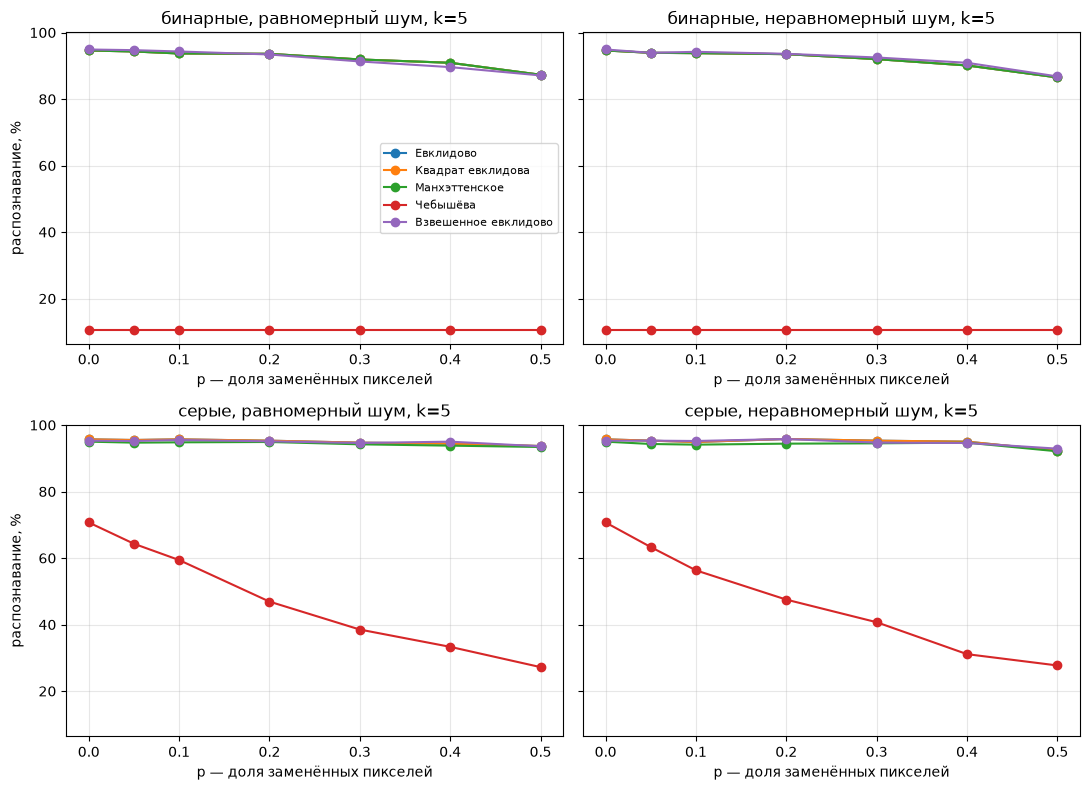

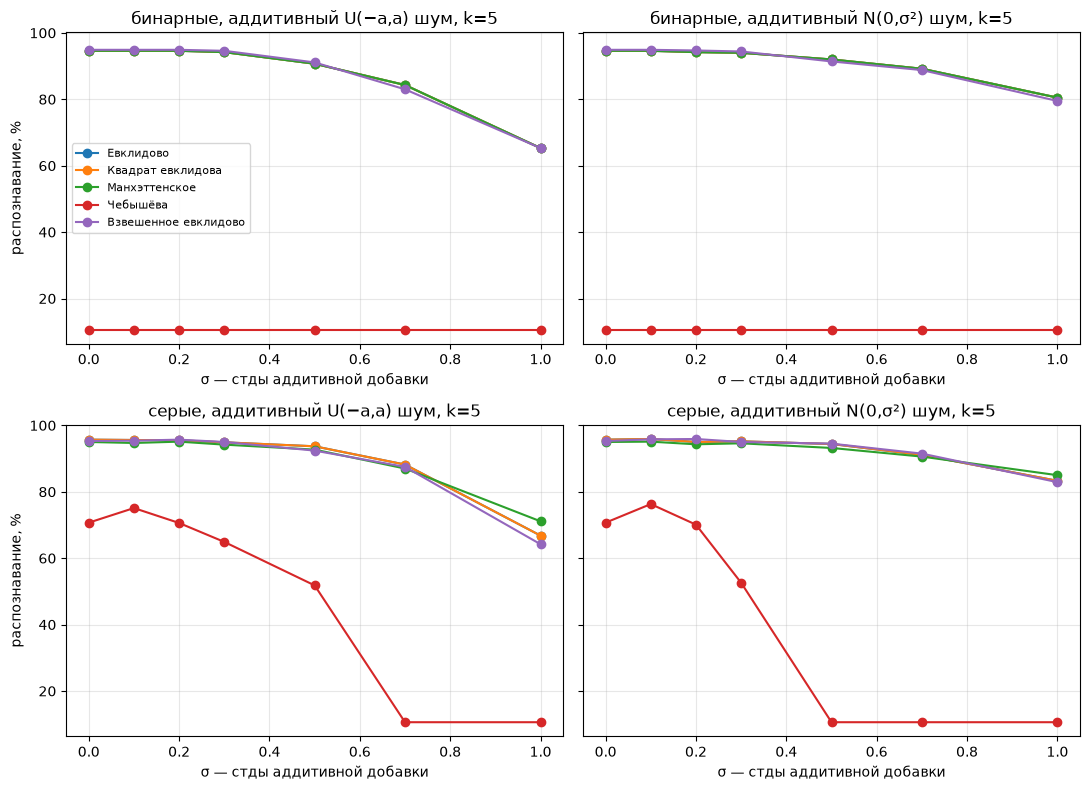

In [17]:
import matplotlib.pyplot as plt


def plot_vs_noise(res, k, noises, xlabel):
    combos = [(t, n) for t in res["тип"].unique() for n in noises]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
    for ax, (t, n) in zip(axes.ravel(), combos):
        sub = res[(res["тип"] == t) & (res["шум"] == n) & (res["k"] == k)]
        for m in MEASURES:
            s = sub[sub["мера"] == m].sort_values("уровень")
            ax.plot(s["уровень"], s["acc"], marker="o", label=m)
        ax.set_title(f"{t}, {n} шум, k={k}")
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("распознавание, %")
    axes[1, 0].set_ylabel("распознавание, %")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_vs_noise(results, 5, NOISE_SPATIAL, "p — доля заменённых пикселей")
plot_vs_noise(results, 5, NOISE_ADDITIVE, "σ — стды аддитивной добавки")

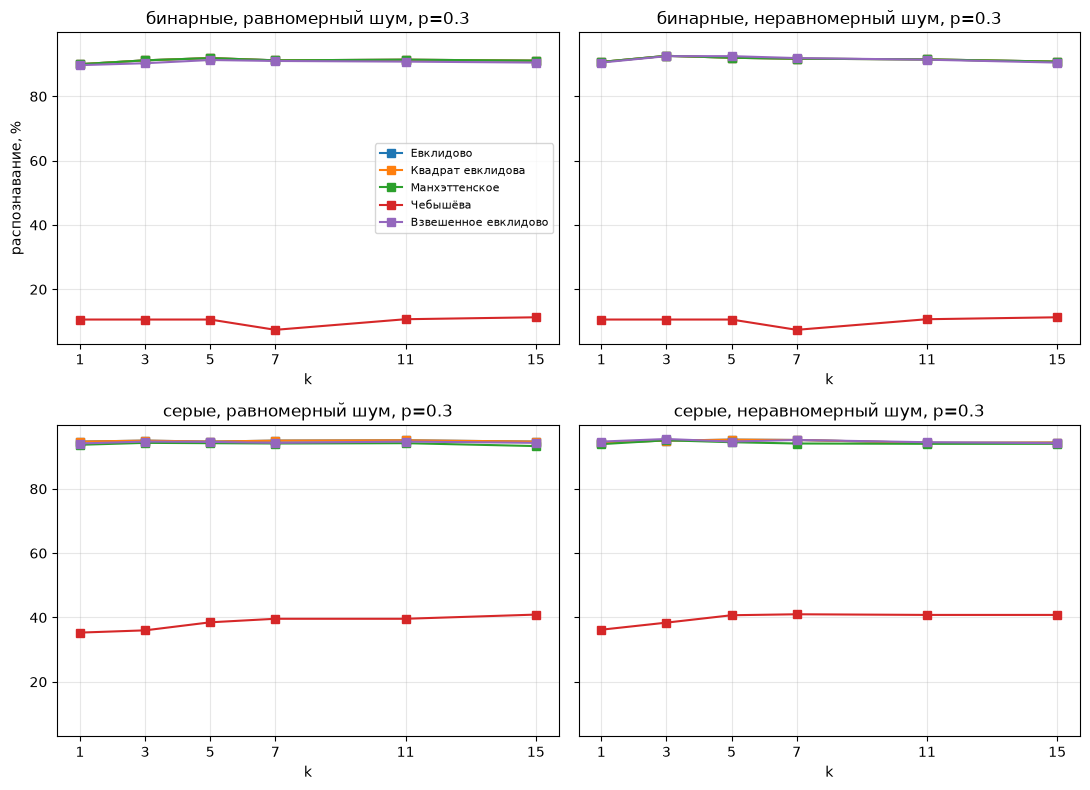

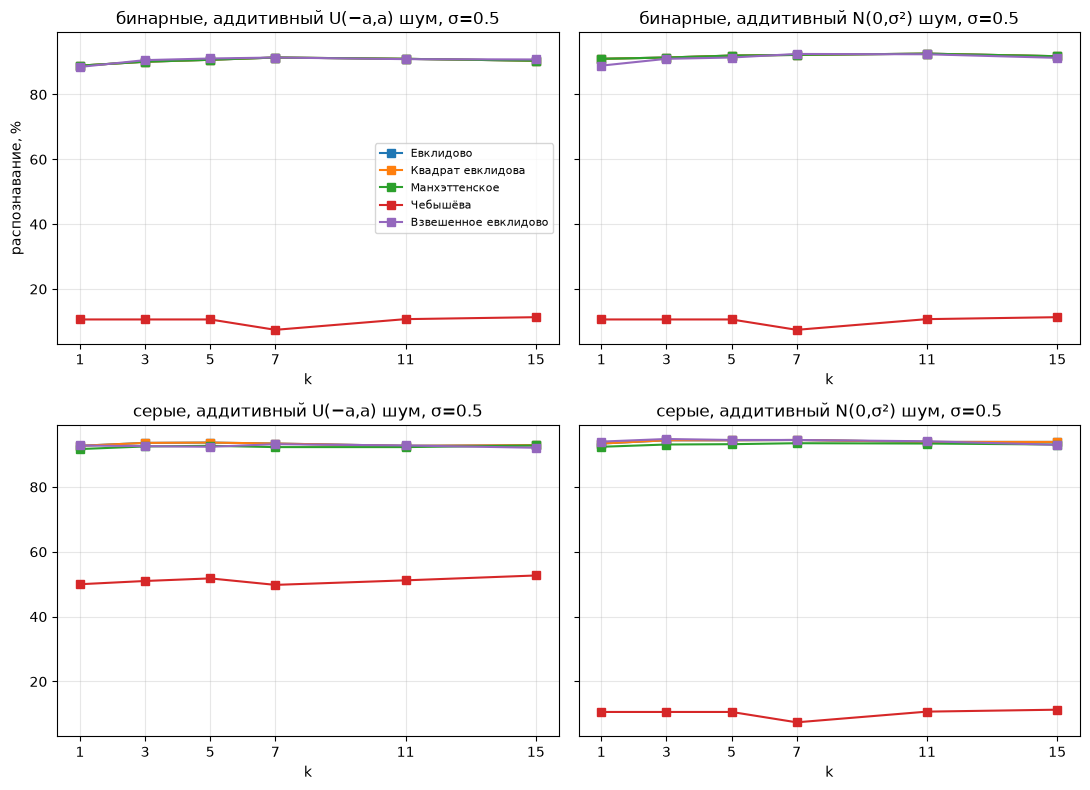

In [18]:
def plot_vs_k(res, level, noises, name="p"):
    combos = [(t, n) for t in res["тип"].unique() for n in noises]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
    for ax, (t, n) in zip(axes.ravel(), combos):
        sub = res[(res["тип"] == t) & (res["шум"] == n) & (res["уровень"] == level)]
        for m in MEASURES:
            s = sub[sub["мера"] == m].sort_values("k")
            ax.plot(s["k"], s["acc"], marker="s", label=m)
        ax.set_title(f"{t}, {n} шум, {name}={level}")
        ax.set_xlabel("k")
        ax.set_xticks(K_LIST)
        ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("распознавание, %")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_vs_k(results, 0.3, NOISE_SPATIAL)
plot_vs_k(results, 0.5, NOISE_ADDITIVE, name="σ")

In [19]:
with pd.option_context("display.width", 200):
    print(
        results[results.k == 5]
        .pivot_table(index=["тип", "шум", "уровень"], columns="мера", values="acc")
        .round(1)
    )

мера                                 Взвешенное евклидово  Евклидово  Квадрат евклидова  Манхэттенское  Чебышёва
тип      шум                уровень                                                                             
бинарные аддитивный N(0,σ²) 0.00                     94.9       94.6               94.6           94.6      10.6
                            0.10                     94.9       94.6               94.6           94.6      10.6
                            0.20                     94.7       94.2               94.2           94.2      10.6
                            0.30                     94.4       94.0               94.0           94.0      10.6
                            0.50                     91.4       92.0               92.0           92.0      10.6
                            0.70                     88.8       89.2               89.2           89.2      10.6
                            1.00                     79.5       80.5               80.5         